In [1]:
# Google Colab Only
try:
    import google.colab  # noqa: F401

    %pip install -q dataeval maite-datasets opencv-python-headless torchvision
except Exception:
    pass

In [2]:
from numbers import Number
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torchvision.transforms.v2 as T
from maite_datasets.image_classification import MilitaryVehicles
from PIL import Image

from dataeval import config
from dataeval.extractors import BoVWExtractor
from dataeval.flags import ImageStats
from dataeval.quality import Duplicates, DuplicatesOutput

config.set_batch_size(64)
config.set_max_processes(4)
config.set_seed(42)

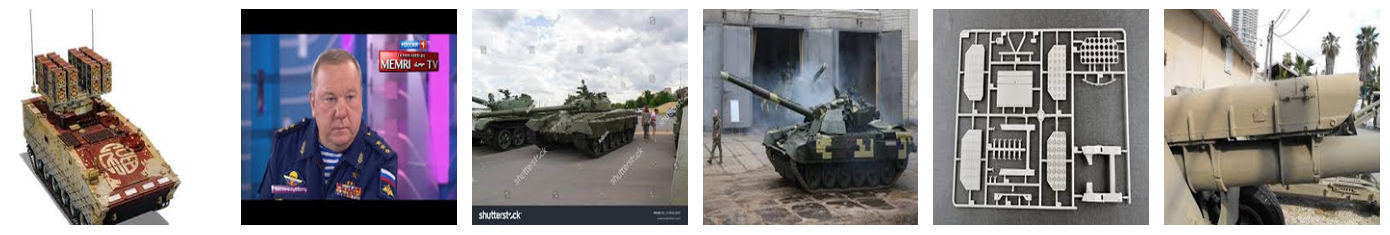

In [3]:
def numpy_to_pil(img: np.ndarray) -> Image.Image:
    """Convert CHW numpy array to PIL Image."""
    return Image.fromarray(np.transpose(img, (1, 2, 0)))


def pil_to_numpy(img: Image.Image) -> np.ndarray:
    """Convert PIL Image to CHW numpy array."""
    return np.transpose(np.array(img), (2, 0, 1))


IMG_SIZE = 224
N_PHOTOS = 12

dataset = MilitaryVehicles("./data", image_set="train", download=True)
photo_ids = np.random.default_rng(1).choice(len(dataset), N_PHOTOS, replace=False)
photos = [
    pil_to_numpy(numpy_to_pil(np.asarray(dataset[int(i)][0])).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS))
    for i in photo_ids
]

# Display six of the images
fig, axes = plt.subplots(1, 6, figsize=(14, 2.5))
for ax, photo in zip(axes, photos, strict=False):
    ax.imshow(np.transpose(photo, (1, 2, 0)))
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
FILL = 128  # Gray fill avoids artificial SIFT edges that black (0) would create


def _n(degrees: int) -> Number:
    """Helper to cast degrees to Number for Pylance."""
    return cast(Number, degrees)


# Helper: rotate with expand=True to preserve full content, then resize back
def _rotate_and_resize(degrees):
    return T.Compose([T.RandomRotation(degrees=(degrees, degrees), expand=True, fill=FILL), T.Resize(IMG_SIZE)])


# Define transformation categories
transformations = {
    # Geometric transformations
    "Rotation 15°": _rotate_and_resize(15),
    "Rotation 45°": _rotate_and_resize(45),
    "Rotation 90°": _rotate_and_resize(90),
    "Rotation 180°": _rotate_and_resize(180),
    "Horizontal Flip": T.RandomHorizontalFlip(p=1.0),
    "Vertical Flip": T.RandomVerticalFlip(p=1.0),
    "Affine (rotate+translate)": T.RandomAffine(degrees=_n(30), translate=(0.1, 0.1), fill=FILL),
    "Affine (rotate+scale)": T.RandomAffine(degrees=_n(15), scale=(0.8, 1.2), fill=FILL),
    "Perspective (mild)": T.RandomPerspective(distortion_scale=0.2, p=1.0, fill=FILL),
    "Perspective (strong)": T.RandomPerspective(distortion_scale=0.5, p=1.0, fill=FILL),
    # Color transformations
    "Brightness +30%": T.ColorJitter(brightness=(1.3, 1.3)),
    "Brightness -30%": T.ColorJitter(brightness=(0.7, 0.7)),
    "Contrast +50%": T.ColorJitter(contrast=(1.5, 1.5)),
    "Saturation +50%": T.ColorJitter(saturation=(1.5, 1.5)),
    "Hue Shift": T.ColorJitter(hue=(0.3, 0.3)),
    "Full ColorJitter": T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    "Grayscale": T.Grayscale(num_output_channels=3),
    "Color Invert": T.RandomInvert(p=1.0),
    # Blur and noise
    "Gaussian Blur (mild)": T.GaussianBlur(kernel_size=5, sigma=(1.0, 1.0)),
    "Gaussian Blur (strong)": T.GaussianBlur(kernel_size=11, sigma=(3.0, 3.0)),
    # Crop and resize
    "Center Crop (80%)": T.Compose([T.CenterCrop(180), T.Resize(IMG_SIZE)]),
    "Center Crop (50%)": T.Compose([T.CenterCrop(112), T.Resize(IMG_SIZE)]),
    "Random Crop (80%)": T.Compose([T.RandomCrop(180), T.Resize(IMG_SIZE)]),
    "Resize Down+Up": T.Compose([T.Resize(112), T.Resize(IMG_SIZE)]),
    "Resize Down+Up (severe)": T.Compose([T.Resize(56), T.Resize(IMG_SIZE)]),
    # Severe transformations
    "Random Erasing (10%)": T.RandomErasing(p=1.0, scale=(0.02, 0.1)),
    "Random Erasing (33%)": T.RandomErasing(p=1.0, scale=(0.2, 0.33)),
    # Combinations (common augmentation pipelines)
    "Augment: Flip+Rotate": T.Compose([
        T.RandomHorizontalFlip(p=1.0),
        T.RandomRotation(degrees=_n(15), expand=True, fill=FILL),
        T.Resize(IMG_SIZE),
    ]),
    "Augment: Flip+Color": T.Compose([
        T.RandomHorizontalFlip(p=1.0),
        T.ColorJitter(brightness=0.2, contrast=0.2),
    ]),
    "Augment: Full Pipeline": T.Compose([
        T.RandomHorizontalFlip(p=0.5),
        T.RandomRotation(degrees=_n(10), expand=True, fill=FILL),
        T.Resize(IMG_SIZE),
        T.ColorJitter(brightness=0.1, contrast=0.1),
        T.GaussianBlur(kernel_size=3, sigma=(0.5, 0.5)),
    ]),
}

In [5]:
# Apply every transformation to every image, with the original first in each block of images
images = []
labels = []
for photo in photos:
    images.append(photo)
    labels.append("Original")
    pil = numpy_to_pil(photo)
    for name, transform in transformations.items():
        torch.manual_seed(42)  # For reproducibility
        images.append(pil_to_numpy(transform(pil)))
        labels.append(name)

BLOCK = len(transformations) + 1  # One original and its copies


def original_of(index: int) -> int:
    """Index of the original that image ``index`` was made from."""
    return index - index % BLOCK


print(f"Created {len(images)} images: {N_PHOTOS} originals and {len(images) - N_PHOTOS} augmented copies")

Created 372 images: 12 originals and 360 augmented copies


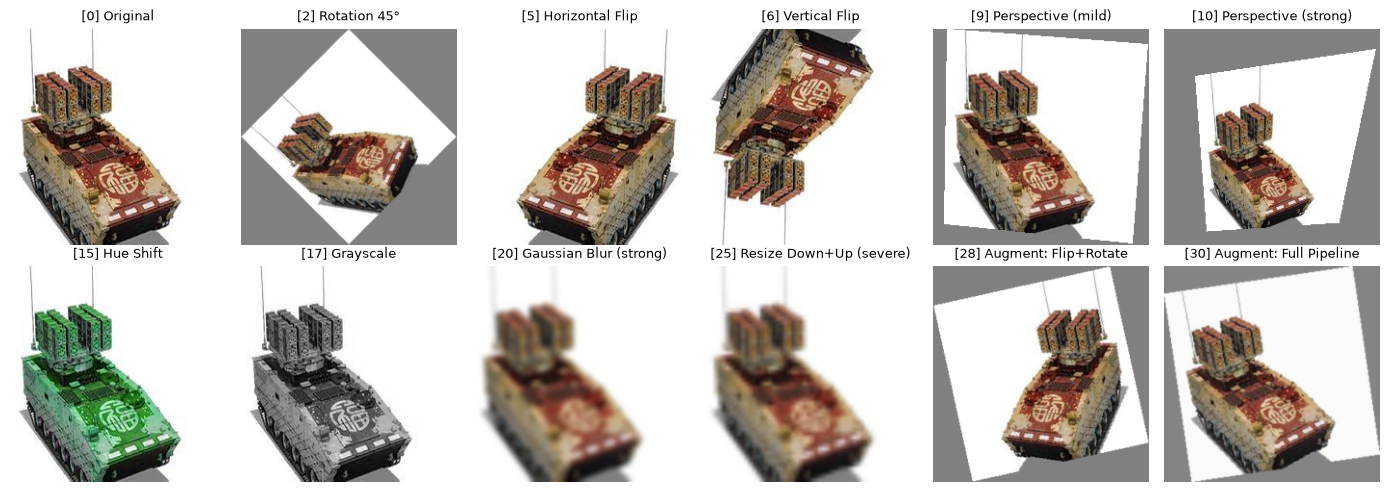

In [6]:
# Visualize a sample of transformations of the first image
sample = [0, 2, 5, 6, 9, 10, 15, 17, 20, 25, 28, 30]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.flatten(), sample, strict=True):
    ax.imshow(np.transpose(images[i], (1, 2, 0)))
    ax.set_title(f"[{i}] {labels[i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
def score(results: DuplicatesOutput) -> dict:
    """Count the copies found, and the groups that mix originals."""
    groups = [sorted(indices) for indices, _ in results.near or []]
    found, grouped = set(), set()
    for group in groups:
        pure = len({original_of(i) for i in group}) == 1
        for i in group:
            if i != original_of(i) and original_of(i) in group:
                grouped.add(i)
                if pure:
                    found.add(i)
    mixed = [len({original_of(i) for i in group}) for group in groups]  # Originals in each group
    return {
        "found": found,
        "grouped": grouped,
        "groups": len(groups),
        "mixed": sum(count > 1 for count in mixed),
        "largest": max(mixed, default=0),
    }

In [8]:
# Method 1: D4 Hash-based detection (rotation/flip invariant at 90° increments)
d4_score = score(Duplicates(flags=ImageStats.HASH_DUPLICATES_D4).evaluate(images))

# Method 2: BoVW-based detection (rotation invariant at any angle)
# Fit the vocabulary once on all of the images, then share the fitted extractor with the detectors below.
bovw_extractor = BoVWExtractor(vocab_size=64).fit(images)
cluster_sensitivity = 2.5
bovw_score = score(
    Duplicates(
        flags=ImageStats.NONE,  # Skip hash computation, use only clustering
        extractor=bovw_extractor,
        batch_size=64,
        cluster_sensitivity=cluster_sensitivity,
    ).evaluate(images)
)

# Method 3: Combined detection (both hashes and BoVW)
combined_score = score(
    Duplicates(
        flags=ImageStats.HASH_DUPLICATES_D4,
        extractor=bovw_extractor,
        cluster_sensitivity=cluster_sensitivity,
    ).evaluate(images)
)

n_copies = len(images) - N_PHOTOS
print(f"{'Method':<10} {'Found':>6} {'Groups':>7} {'Mixed groups':>13} {'Originals in the largest group':>30}")
for name, result in {"D4": d4_score, "BoVW": bovw_score, "Combined": combined_score}.items():
    print(
        f"{name:<10} {100 * len(result['found']) / n_copies:>5.0f}% {result['groups']:>7} {result['mixed']:>13}"
        f" {result['largest']:>30}"
    )

/builds/jatic/aria/dataeval/src/dataeval/types/_output.py:359: FutureWarning: The default value of hash_radius will change from 0 in a future major release, so that Duplicates finds the perceptual near-duplicates it documents rather than only bit-identical ones (5 of 64 bits is the expected value). Pass hash_radius explicitly to pin the current behavior and silence this warning.
  result = fn(*args, **kwargs)


OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.


/builds/jatic/aria/dataeval/src/dataeval/types/_output.py:359: FutureWarning: The default value of hash_radius will change from 0 in a future major release, so that Duplicates finds the perceptual near-duplicates it documents rather than only bit-identical ones (5 of 64 bits is the expected value). Pass hash_radius explicitly to pin the current behavior and silence this warning.
  result = fn(*args, **kwargs)


Method      Found  Groups  Mixed groups Originals in the largest group
D4            48%      15             0                              1
BoVW          54%      31             1                              6
Combined      71%      20             1                              6


In [9]:
names = list(transformations)
rates = pl.DataFrame({
    "Transformation": names,
    **{
        method: [
            round(100 * sum(BLOCK * photo + 1 + k in result["found"] for photo in range(N_PHOTOS)) / N_PHOTOS)
            for k in range(len(names))
        ]
        for method, result in {"D4 Hash": d4_score, "BoVW": bovw_score, "Combined": combined_score}.items()
    },
})
with pl.Config(tbl_rows=len(names), fmt_str_lengths=40):
    print(rates)

shape: (30, 4)
┌───────────────────────────┬─────────┬──────┬──────────┐
│ Transformation            ┆ D4 Hash ┆ BoVW ┆ Combined │
│ ---                       ┆ ---     ┆ ---  ┆ ---      │
│ str                       ┆ i64     ┆ i64  ┆ i64      │
╞═══════════════════════════╪═════════╪══════╪══════════╡
│ Rotation 15°              ┆ 0       ┆ 50   ┆ 50       │
│ Rotation 45°              ┆ 0       ┆ 33   ┆ 33       │
│ Rotation 90°              ┆ 100     ┆ 100  ┆ 100      │
│ Rotation 180°             ┆ 100     ┆ 100  ┆ 100      │
│ Horizontal Flip           ┆ 100     ┆ 75   ┆ 100      │
│ Vertical Flip             ┆ 100     ┆ 75   ┆ 100      │
│ Affine (rotate+translate) ┆ 0       ┆ 50   ┆ 50       │
│ Affine (rotate+scale)     ┆ 0       ┆ 50   ┆ 50       │
│ Perspective (mild)        ┆ 0       ┆ 50   ┆ 50       │
│ Perspective (strong)      ┆ 0       ┆ 17   ┆ 17       │
│ Brightness +30%           ┆ 50      ┆ 92   ┆ 92       │
│ Brightness -30%           ┆ 92      ┆ 92   ┆ 100      │

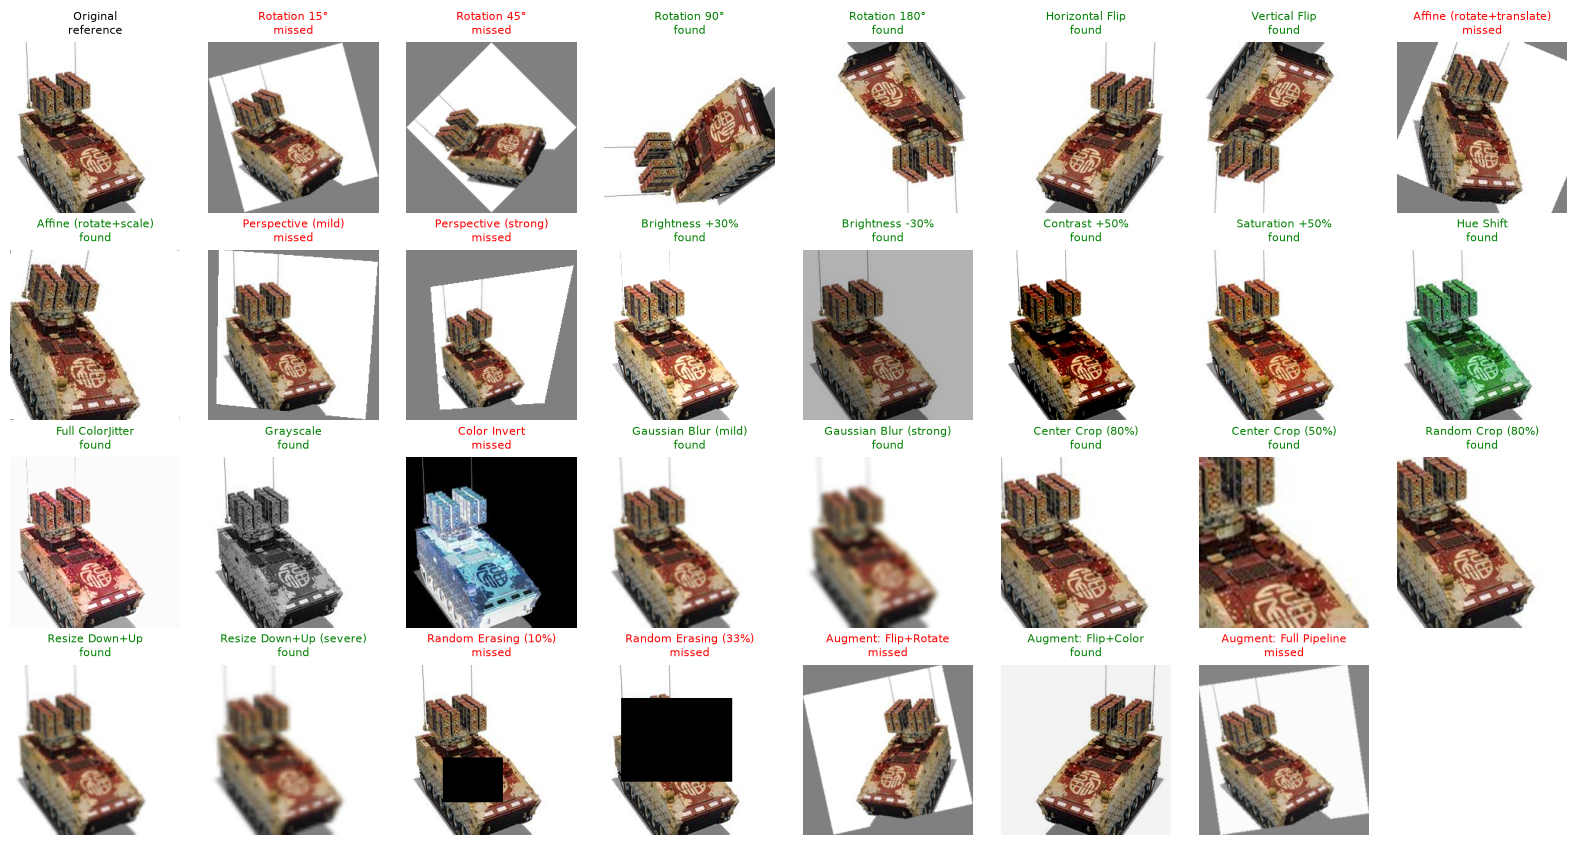

In [10]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for ax in axes.flatten():
    ax.axis("off")
for ax, i in zip(axes.flatten(), range(BLOCK), strict=False):
    ax.imshow(np.transpose(images[i], (1, 2, 0)))
    status = "reference" if i == 0 else ("found" if i in combined_score["found"] else "missed")
    ax.set_title(
        f"{labels[i]}\n{status}", fontsize=8, color={"reference": "black", "found": "green", "missed": "red"}[status]
    )
plt.tight_layout()
plt.show()

In [11]:
thresholds = [1.0, 1.75, 2.5, 3.5, 5.0]
sweep = {
    t: score(Duplicates(flags=ImageStats.NONE, extractor=bovw_extractor, cluster_sensitivity=t).evaluate(images))
    for t in thresholds
}
print(f"{'Sensitivity':>11} {'Grouped with original':>22} {'Found':>7} {'Originals in the largest group':>30}")
for t, result in sweep.items():
    print(
        f"{t:>11} {100 * len(result['grouped']) / n_copies:>21.0f}% {100 * len(result['found']) / n_copies:>6.0f}%"
        f" {result['largest']:>30}"
    )

Sensitivity  Grouped with original   Found Originals in the largest group
        1.0                    11%     11%                              1
       1.75                    27%     27%                              2
        2.5                    54%     54%                              6
        3.5                    87%      8%                             11
        5.0                    99%      8%                             11


In [12]:
FAMILIES = (
    ("Rotation 15", "Small rotation"),
    ("Rotation 45", "Small rotation"),
    ("Rotation 90", "Rotation 90/180"),
    ("Rotation 180", "Rotation 90/180"),
    ("Horizontal Flip", "Flip"),
    ("Vertical Flip", "Flip"),
    ("Affine", "Affine"),
    ("Perspective", "Perspective"),
    ("Brightness", "Color"),
    ("Contrast", "Color"),
    ("Saturation", "Color"),
    ("Hue", "Color"),
    ("Full ColorJitter", "Color"),
    ("Grayscale", "Grayscale"),
    ("Color Invert", "Invert"),
    ("Gaussian Blur", "Blur"),
    ("Center Crop", "Crop"),
    ("Random Crop", "Crop"),
    ("Resize", "Resize"),
    ("Random Erasing", "Erasing"),
    ("Augment", "Pipeline"),
)


def family(label: str) -> str:
    """Name the family of a transformation from the start of its label."""
    return next(name for prefix, name in FAMILIES if label.startswith(prefix))


members: dict[str, list[int]] = {}
for k, name in enumerate(names):
    members.setdefault(family(name), []).extend(BLOCK * photo + 1 + k for photo in range(N_PHOTOS))

family_rates = {
    name: [
        round(100 * len(set(indices) & result["found"]) / len(indices))
        for result in (d4_score, bovw_score, combined_score)
    ]
    for name, indices in members.items()
}
print(f"{'Family':<16} {'Copies':>6} {'D4':>5} {'BoVW':>6} {'Combined':>9}")
for name, (d4, bovw, combined) in family_rates.items():
    print(f"{name:<16} {len(members[name]):>6} {d4:>4}% {bovw:>5}% {combined:>8}%")

Family           Copies    D4   BoVW  Combined
Small rotation       24    0%    42%       42%
Rotation 90/180      24  100%   100%      100%
Flip                 24  100%    75%      100%
Affine               24    0%    50%       50%
Perspective          24    0%    33%       33%
Color                72   78%    93%       97%
Grayscale            12  100%   100%      100%
Invert               12    0%     0%        0%
Blur                 24   96%     4%      100%
Crop                 36    0%    47%       47%
Resize               24   92%     4%      100%
Erasing              24    0%    46%       46%
Pipeline             36   31%    42%       50%


In [13]:
# TEST ASSERTION CELL ###
# The collection
assert (len(images), BLOCK, n_copies) == (372, 31, 360)

# No detector but a loose BoVW setting merges originals
assert d4_score["mixed"] == 0
assert d4_score["largest"] == 1
share = {
    name: len(result["found"]) / n_copies
    for name, result in (("d4", d4_score), ("bovw", bovw_score), ("comb", combined_score))
}
assert 0.4 < share["d4"] < 0.55
assert 0.45 < share["bovw"] < 0.65
assert share["comb"] > max(share["d4"], share["bovw"])
assert 0.6 < share["comb"] < 0.8

# The families the text describes
d4, bovw, combined = ({name: rates[i] for name, rates in family_rates.items()} for i in range(3))
assert all(d4[name] == 100 for name in ("Rotation 90/180", "Flip", "Grayscale"))
assert all(d4[name] > 70 for name in ("Color", "Blur", "Resize"))
assert all(d4[name] == 0 for name in ("Small rotation", "Affine", "Perspective", "Crop", "Erasing"))
assert all(bovw[name] > 20 for name in ("Small rotation", "Affine", "Perspective", "Crop", "Erasing"))
assert all(bovw[name] < 15 for name in ("Blur", "Resize"))
assert all(
    rates[0] < 10 and rates[1] < 10 and rates[2] < 10 for name, rates in family_rates.items() if name == "Invert"
)
assert all(combined[name] >= max(d4[name], bovw[name]) for name in family_rates)

# The sensitivity sweep: more copies share a group with their original as the sensitivity rises, and the groups merge
grouped = [len(sweep[t]["grouped"]) / n_copies for t in thresholds]
assert grouped == sorted(grouped)
assert grouped[0] < 0.2
assert grouped[-1] > 0.9
found_by = {t: len(sweep[t]["found"]) / n_copies for t in thresholds}
assert found_by[1.0] < found_by[1.75] < found_by[2.5]
assert 0.15 < found_by[1.75] < 0.4
assert found_by[3.5] < 0.2
assert found_by[5.0] < 0.2
assert sweep[3.5]["largest"] >= 9